# 1 · Pendubot dynamics and numerical simulation

**Question:** How does one motor move two links, and how does the Python code predict that motion?

You will connect the coordinates to the equations, inspect each model function,
simulate passive motion, and check energy and automatic derivatives.

Estimated study time: 25–35 minutes. Computation normally takes seconds after compilation.

Run cells from top to bottom using **Kernel → Restart Kernel and Run All Cells**.
Each notebook starts independently and imports the real project files. Python 3 with
the packages in `requirements-notebooks.txt` is required; see `README.txt` in this folder.
The delivered outputs were executed, not typed example results. Rerunning updates them.

## 1. Import the project
`numpy` handles arrays and plotting data. `jax.numpy` supports differentiable computations. `Config` holds model and solver settings.

In [1]:
from pathlib import Path
import sys, inspect, json, csv
from dataclasses import asdict, replace
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code, HTML, Image

# Works when Jupyter starts in this notebook folder, the project root,
# or the original workspace. No Windows-specific absolute path is needed.
def find_project():
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent, parent / 'pendubot_simulation',
                          parent / 'Pendubot_Opt_Control',
                          parent / 'outputs' / 'pendubot_simulation',
                          parent / 'outputs' / 'Pendubot_Opt_Control'):
            if (candidate / 'pendubot.py').is_file():
                return candidate.resolve()
    raise FileNotFoundError('Keep notebooks/ inside the Pendubot project folder.')

PROJECT = find_project()
sys.path.insert(0, str(PROJECT))
from pendubot import Config, Solver, X0, GOAL, mass_matrix, dynamics, rk4, energy

def show_source(obj):
    # Display the actual implementation rather than a separately maintained copy.
    display(Code(inspect.getsource(obj), language='python'))

def show_table(rows, columns=None):
    if not rows:
        print('No rows.'); return
    columns = columns or list(rows[0])
    def fmt(value):
        if isinstance(value, (float, np.floating)):
            return f'{value:.6g}'
        return str(value)
    lines = ['| ' + ' | '.join(columns) + ' |',
             '| ' + ' | '.join(['---'] * len(columns)) + ' |']
    lines += ['| ' + ' | '.join(fmt(row.get(c, '')) for c in columns) + ' |'
              for row in rows]
    display(Markdown('\n'.join(lines)))

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True,
                     'grid.alpha': 0.22, 'font.size': 11})
print('Python:', sys.version.split()[0], '| JAX:', jax.__version__)
print('JAX uses 64-bit arithmetic:', jax.config.x64_enabled)
print('Project located successfully.')

Python: 3.14.7 | JAX: 0.12.0.1
JAX uses 64-bit arithmetic: True
Project located successfully.


## 2. Coordinates, states, and editable parameters

The state is $x=[q_1,q_2,v_1,v_2]^T$, with $v_i=\dot q_i$.
$q_1=0$ points **downward**. The second coordinate is relative to link 1,
so link 2 has absolute angle $q_1+q_2$. The motor torque is $u$ at the base;
the generalized force is $[u,0]^T$. Dynamic coupling moves the passive elbow.

The hanging state is $[0,0,0,0]$ and the extended upright goal is $[\pi,0,0,0]$.
Angles are radians, lengths metres, masses kilograms, torque N·m, and time seconds.
`Config` is a frozen dataclass: use `replace(cfg, m2=...)` to create a changed setting.

In [2]:
cfg = Config()
show_source(Config)
show_table([{'parameter': key, 'value': value} for key, value in asdict(cfg).items()])
print('Number of control intervals:', cfg.n)
print('Actual planning horizon:', cfg.n * cfg.dt, 's')

@dataclass(frozen=True)
class Config:
    dt: float = 0.02
    duration: float = 6.0
    # Uniform 1 kg, 1 m rods, COM at 0.5 m, COM inertia 1/12 kg m^2.
    m1: float = 1.0
    m2: float = 1.0
    l1: float = 1.0
    l2: float = 1.0
    gravity: float = 9.81
    q: tuple = (1.0, 1.0, 0.1, 0.1)
    q_terminal: tuple = (2000.0, 2000.0, 200.0, 200.0)
    r: float = 0.01
    max_iterations: int = 1500
    relative_tolerance: float = 1e-8
    control_tolerance: float = 1e-3

    @property
    def n(self):
        return int(round(self.duration / self.dt))

| parameter | value |
| --- | --- |
| dt | 0.02 |
| duration | 6 |
| m1 | 1 |
| m2 | 1 |
| l1 | 1 |
| l2 | 1 |
| gravity | 9.81 |
| q | (1.0, 1.0, 0.1, 0.1) |
| q_terminal | (2000.0, 2000.0, 200.0, 200.0) |
| r | 0.01 |
| max_iterations | 1500 |
| relative_tolerance | 1e-08 |
| control_tolerance | 0.001 |

Number of control intervals: 300
Actual planning horizon: 6.0 s


### Draw the coordinate convention
For a vertical-upward plotting axis, a link endpoint is $[l\sin q,-l\cos q]$.
The code below uses $q_1+q_2$ for the second link; treating both coordinates as
absolute angles would give a different robot model.

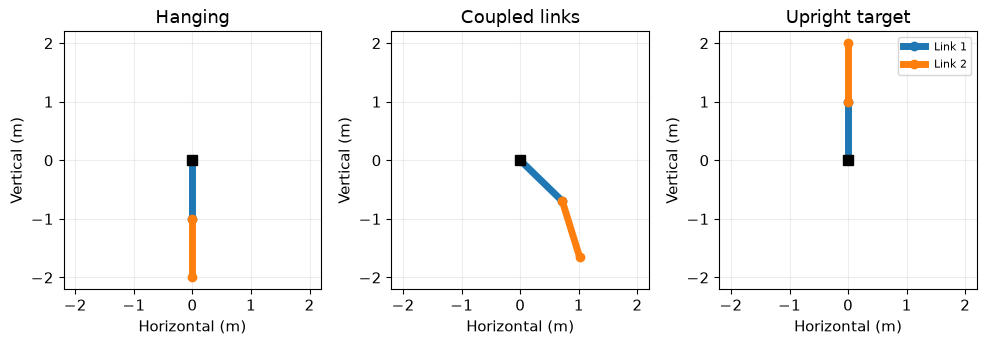

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, (q1, q2), title in zip(axes, [(0, 0), (0.8, -0.5), (np.pi, 0)],
                              ['Hanging', 'Coupled links', 'Upright target']):
    p1 = np.array([cfg.l1*np.sin(q1), -cfg.l1*np.cos(q1)])
    p2 = p1 + [cfg.l2*np.sin(q1+q2), -cfg.l2*np.cos(q1+q2)]
    ax.plot([0, p1[0]], [0, p1[1]], 'o-', lw=5, label='Link 1')
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]], 'o-', lw=5, label='Link 2')
    ax.plot(0, 0, 'ks', ms=7)
    ax.set(xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), title=title, aspect='equal',
           xlabel='Horizontal (m)', ylabel='Vertical (m)')
axes[-1].legend(fontsize=8)
fig.tight_layout(); display(fig); plt.close(fig)

## 3. The mass matrix: `mass_matrix(q, cfg)`

Uniform rods have $l_{ci}=l_i/2$ and centre-of-mass inertia $I_i=m_i l_i^2/12$.
Define $b=m_2l_1l_{c2}$, $d=I_2+m_2l_{c2}^2$,
$a=I_1+m_1l_{c1}^2+m_2l_1^2+d$. Then

$$M(q)=\begin{bmatrix}a+2b\cos q_2&d+b\cos q_2\\d+b\cos q_2&d\end{bmatrix}.$$

The off-diagonal entries couple the accelerations. `jnp.array` constructs a
2×2 differentiable matrix; `q[1]` selects $q_2$. The mass matrix is symmetric
and positive definite for the positive physical parameters used here.

In [4]:
show_source(mass_matrix)
M = np.asarray(mass_matrix(jnp.zeros(2), cfg))
print('M at the hanging configuration:\n', M)
print('Eigenvalues:', np.linalg.eigvalsh(M))
assert np.allclose(M, M.T)
assert np.linalg.eigvalsh(M).min() > 0

def mass_matrix(q, cfg=Config()):
    lc1, lc2 = cfg.l1 / 2, cfg.l2 / 2
    i1, i2 = cfg.m1 * cfg.l1**2 / 12, cfg.m2 * cfg.l2**2 / 12
    b = cfg.m2 * cfg.l1 * lc2
    d = i2 + cfg.m2 * lc2**2
    a = i1 + cfg.m1 * lc1**2 + cfg.m2 * cfg.l1**2 + d
    return jnp.array([[a + 2*b*jnp.cos(q[1]), d + b*jnp.cos(q[1])],
                      [d + b*jnp.cos(q[1]), d]])

M at the hanging configuration:
 [[2.66666667 0.83333333]
 [0.83333333 0.33333333]]
Eigenvalues: [0.06627912 2.93372088]


## 4. Continuous dynamics: `dynamics(x, u, cfg)`

The Euler–Lagrange equations are
$$M(q)\ddot q+c(q,v)+G(q)=\begin{bmatrix}u\\0\end{bmatrix},\qquad
\dot x=\begin{bmatrix}v\\M^{-1}([u,0]^T-c-G)\end{bmatrix}.$$

$$c=\begin{bmatrix}-b\sin q_2(2v_1v_2+v_2^2)\\b\sin q_2 v_1^2\end{bmatrix},\quad
G=\begin{bmatrix}(m_1l_{c1}+m_2l_1)g\sin q_1+m_2l_{c2}g\sin(q_1+q_2)\\m_2l_{c2}g\sin(q_1+q_2)\end{bmatrix}.$$

In the source, `c` contains velocity-dependent forces, `g` contains gravity,
and `rhs` is applied torque minus those forces. `det` and `acc` implement the
explicit 2×2 solve. `jnp.concatenate((x[2:], acc))` returns the four state derivatives.
The function does not contain friction, sensor noise, or torque saturation.

In [5]:
show_source(dynamics)
print('Hanging, no torque:', np.asarray(dynamics(X0, 0., cfg)))
print('Upright, no torque:', np.asarray(dynamics(GOAL, 0., cfg)))
print('Hanging, 1 N m torque:', np.asarray(dynamics(X0, 1., cfg)))
assert np.linalg.norm(np.asarray(dynamics(GOAL, 0., cfg))) < 1e-12

def dynamics(x, u, cfg=Config()):
    q1, q2, v1, v2 = x
    b = cfg.m2 * cfg.l1 * cfg.l2 / 2
    c = jnp.array([-b*jnp.sin(q2)*(2*v1*v2 + v2*v2),
                   b*jnp.sin(q2)*v1*v1])
    g2 = cfg.m2 * cfg.gravity * cfg.l2/2 * jnp.sin(q1+q2)
    g = jnp.array([(cfg.m1*cfg.l1/2 + cfg.m2*cfg.l1)
                   *cfg.gravity*jnp.sin(q1) + g2, g2])
    rhs = jnp.array([jnp.ravel(jnp.asarray(u))[0], 0.0]) - c - g
    # Explicit 2x2 solve avoids an unnecessary general solver in higher AD.
    m = mass_matrix(x[:2], cfg)
    det = m[0, 0]*m[1, 1] - m[0, 1]*m[1, 0]
    acc = jnp.array([m[1, 1]*rhs[0]-m[0, 1]*rhs[1],
                     -m[1, 0]*rhs[0]+m[0, 0]*rhs[1]]) / det
    return jnp.concatenate((x[2:], acc))

Hanging, no torque: [0. 0. 0. 0.]
Upright, no torque: [ 0.00000000e+00  0.00000000e+00 -1.54462951e-15  2.05950602e-15]
Hanging, 1 N m torque: [ 0.          0.          1.71428571 -4.28571429]


## 5. From derivatives to states: `rk4`

`dynamics` returns a rate, not the next state. RK4 evaluates that rate at four
intermediate states while holding $u$ constant for one sample:

$$k_1=f(x,u),\quad k_2=f(x+\tfrac{\Delta t}{2}k_1,u),\quad
k_3=f(x+\tfrac{\Delta t}{2}k_2,u),\quad k_4=f(x+\Delta t k_3,u),$$
$$F(x,u)=x+\frac{\Delta t}{6}(k_1+2k_2+2k_3+k_4).$$

The source calls these stages `a`, `b`, `c`, and `d`. Here `c` is a stage,
whereas inside `dynamics` it names the velocity-dependent force vector.
`Solver.step` compiles this map with `jax.jit`. `fine_step` applies ten smaller
RK4 steps, holding the same control over the original interval.

In [6]:
show_source(rk4)
solver = Solver(cfg)
x_example = jnp.array([0.5, -0.3, 0.2, -0.1])
coarse_next = np.asarray(solver.step(x_example, jnp.zeros(1)))
fine_next = np.asarray(solver.fine_step(x_example, jnp.zeros(1)))
print('One RK4 step:', coarse_next)
print('Ten substeps:', fine_next)
print('Maximum difference:', np.max(np.abs(coarse_next-fine_next)))

def rk4(x, u, dt, cfg=Config()):
    a = dynamics(x, u, cfg)
    b = dynamics(x + dt*a/2, u, cfg)
    c = dynamics(x + dt*b/2, u, cfg)
    d = dynamics(x + dt*c, u, cfg)
    return x + dt/6*(a + 2*b + 2*c + d)

One RK4 step: [ 0.50225111 -0.29833059  0.02505887  0.26684314]
Ten substeps: [ 0.50225111 -0.29833058  0.02505841  0.26684456]
Maximum difference: 1.4192773728494146e-06


## 6. Energy and an unforced simulation

The total mechanical energy is $E=\frac12 v^TMv+V$ with
$$V=-(m_1l_{c1}+m_2l_1)g\cos q_1-m_2l_{c2}g\cos(q_1+q_2).$$
For the ideal model, $\dot E=u v_1$. With zero torque, energy should stay
constant up to numerical integration error. The two runs below use the same
sample times and zero input; only the integration fidelity changes.
`jax.lax.scan` carries the state through time without a Python loop in the compiled function.

def energy(x, cfg=Config()):
    kinetic = 0.5 * x[2:] @ mass_matrix(x[:2], cfg) @ x[2:]
    potential = -(cfg.m1*cfg.l1/2 + cfg.m2*cfg.l1)*cfg.gravity*jnp.cos(x[0])
    potential -= cfg.m2*cfg.l2/2*cfg.gravity*jnp.cos(x[0]+x[1])
    return kinetic + potential

One RK4 step maximum energy drift: 2.0495480292481716e-05 J
Ten RK4 substeps maximum energy drift: 2.858691061646823e-10 J


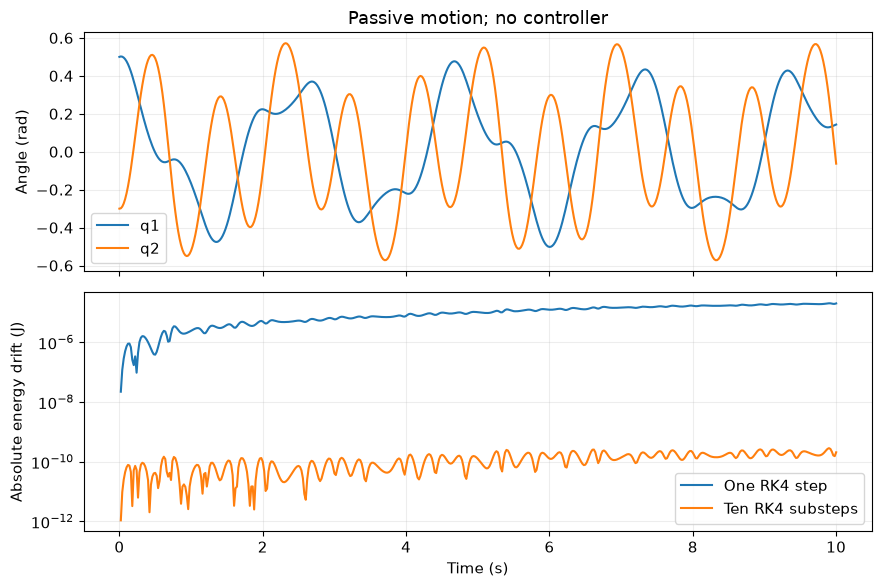

In [7]:
show_source(energy)
samples = round(10 / cfg.dt)
def passive_trajectory(step):
    def body(x, _):
        xn = step(x, jnp.zeros(1))
        return xn, xn
    _, states = jax.jit(lambda x: jax.lax.scan(body, x, None, length=samples))(x_example)
    return jnp.vstack([x_example, states])

passive_coarse = passive_trajectory(solver.step)
passive_fine = passive_trajectory(solver.fine_step)
time = np.arange(samples+1)*cfg.dt
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(time, np.asarray(passive_fine[:, :2]), label=['q1', 'q2'])
axes[0].set(ylabel='Angle (rad)', title='Passive motion; no controller'); axes[0].legend()
for label, states in [('One RK4 step', passive_coarse), ('Ten RK4 substeps', passive_fine)]:
    energies = np.asarray(jax.vmap(lambda x: energy(x, cfg))(states))
    drift = np.abs(energies-energies[0])
    axes[1].semilogy(time[1:], np.maximum(drift[1:], 1e-16), label=label)
    print(label, 'maximum energy drift:', drift.max(), 'J')
axes[1].set(xlabel='Time (s)', ylabel='Absolute energy drift (J)'); axes[1].legend()
fig.tight_layout(); display(fig); plt.close(fig)

## 7. Derivatives used by the optimizer

The optimizer differentiates the **complete RK4 map** $F$, including all stages.
For $z=[x,u]\in\mathbb R^5$, `packed(z)` returns four next-state coordinates.
`jacfwd` returns a Jacobian of shape `(4,5)`; the first four columns are $A=F_x$
and the last is $B=F_u$. A second derivative has shape `(4,5,5)`.
`vmap` applies a function to every time sample in a batch. `jit` compiles it;
the first call can take longer. These derivatives are not simply $I+\Delta t f_x$.

In [8]:
z = jnp.array([0.4, -0.3, 0.8, -0.4, 0.5])
J = np.asarray(solver.derivatives(z[None, :])[0])
H = np.asarray(solver.hessians(z[None, :])[0])
eps = 1e-5
basis = np.eye(5)
def next_state(zz):
    return np.asarray(solver.step(jnp.asarray(zz[:4]), jnp.asarray(zz[4:])))
J_fd = np.column_stack([(next_state(np.asarray(z)+eps*d)-next_state(np.asarray(z)-eps*d))/(2*eps)
                        for d in basis])
print('Jacobian shape:', J.shape, '| Hessian shape:', H.shape)
print('AD versus central finite difference:', np.max(np.abs(J-J_fd)))
assert J.shape == (4, 5) and H.shape == (4, 5, 5)
assert np.max(np.abs(J-J_fd)) < 1e-7

Jacobian shape: (4, 5) | Hessian shape: (4, 5, 5)
AD versus central finite difference: 6.214057046705079e-12


### Run the project’s independent model checks
`model_checks` checks equilibria, mass-matrix eigenvalues, unforced energy drift, and finite-difference Jacobians and Hessians. Passing these is evidence of implementation consistency; it is not a hardware validation.

In [9]:
from run_simulation import model_checks
checks = model_checks(solver)
show_table([{'check': key, 'measured value': value} for key, value in checks.items()])

| check | measured value |
| --- | --- |
| equilibrium_max_residual | 3.60414e-15 |
| mass_matrix_min_eigenvalue | 0.0662791 |
| energy_drift_coarse_joule | 2.04955e-05 |
| energy_drift_fine_joule | 2.85873e-10 |
| jacobian_fd_max_error | 6.21406e-12 |
| hessian_fd_max_error | 4.86191e-10 |

## 8. A small parameter experiment

Changing a link's mass also changes its uniform-rod inertia. The comparison below
starts both models in the same state with the same base torque. It examines the
instantaneous acceleration only; it does not rerun an optimized swing-up.

In [10]:
heavier = replace(cfg, m2=1.5)  # Change this number and rerun this cell.
state = jnp.array([0.4, -0.2, 0., 0.])
show_table([{'link 2 mass (kg)': c.m2,
             'q1 acceleration (rad/s²)': float(dynamics(state, 2., c)[2]),
             'q2 acceleration (rad/s²)': float(dynamics(state, 2., c)[3])}
            for c in [cfg, heavier]])

| link 2 mass (kg) | q1 acceleration (rad/s²) | q2 acceleration (rad/s²) |
| --- | --- | --- |
| 1 | -3.74871 | 6.33627 |
| 1.5 | -4.63845 | 8.53401 |

## Check your understanding

1. Why can the elbow accelerate when its applied torque is zero?
2. Why must the drawing use `q1 + q2` for link 2?
3. What does energy drift measure, and why does finer integration reduce it?
4. What are the shapes of $F_x$, $F_u$, and the packed Hessian?

Next: **02_DDP_and_iLQR_Code_Walkthrough.ipynb**. Equations are developed in
`../DERIVATION.txt`; the implementation inspected here is `../pendubot.py`.